In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [4]:
df = pd.read_csv(r"C:\Users\Dhruvang\Downloads\housing.csv")
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [5]:
print("-" * 40)
df.info()
display(df.describe())
print(df.columns.tolist())

----------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


In [6]:
print("-" * 40)

print(df.isnull().sum())
print(df.duplicated().sum())

print(df["ocean_proximity"].value_counts())

----------------------------------------
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64
0
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


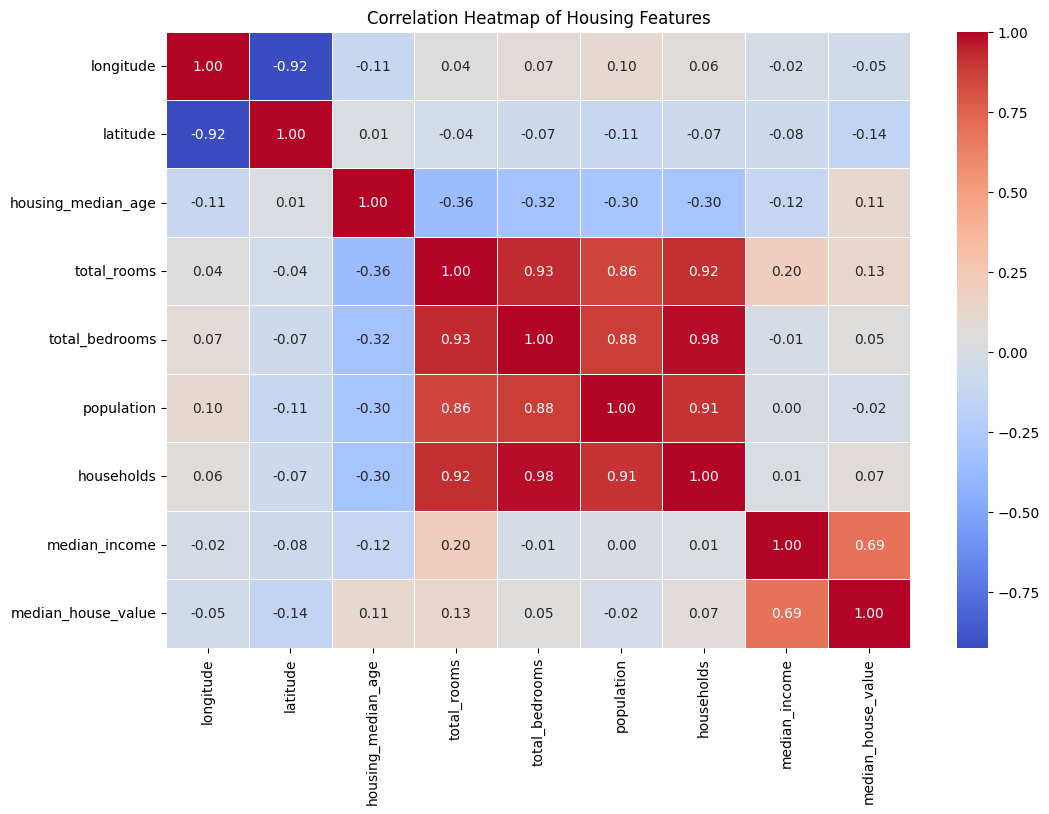

In [7]:
numerical_df = df.select_dtypes(include=np.number)
correlation = numerical_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Housing Features")
plt.show()

In [8]:
# Create a copy of original dataset

df_model = df.copy()

# Average rooms per household
df_model['rooms_per_household'] = (
    df_model['total_rooms'] / df_model['households']
)

# Average bedrooms per room
df_model['bedrooms_per_room'] = (
    df_model['total_bedrooms'] / df_model['total_rooms']
)

# Population per household
df_model['population_per_household'] = (
    df_model['population'] / df_model['households']
)

# Interaction feature
df_model['income_x_rooms'] = (
    df_model['median_income'] * df_model['rooms_per_household']
)

print("Feature engineering completed!")

display(df_model.head())

Feature engineering completed!


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household,income_x_rooms
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556,58.144254
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842,51.785271
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260,60.150315
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945,32.827897
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467,24.161264


In [9]:
# Independent variables
X = df_model.drop('median_house_value', axis=1)

# Dependent variable
y = df_model['median_house_value']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nNumerical Features:")
print(X.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Features:")
print(X.select_dtypes(exclude=np.number).columns.tolist())

Feature Shape: (20640, 13)
Target Shape: (20640,)

Numerical Features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_rooms']

Categorical Features:
['ocean_proximity']


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (16512, 13)
Testing Features: (4128, 13)
Training Target: (16512,)
Testing Target: (4128,)


In [11]:
# Identify numerical and categorical columns

numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

Numerical Features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_rooms']

Categorical Features: ['ocean_proximity']


In [12]:
# Numerical preprocessing pipeline

numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

print("Numerical preprocessing pipeline created!")

Numerical preprocessing pipeline created!


In [13]:
# Categorical preprocessing pipeline

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

print("Categorical preprocessing pipeline created!")

Categorical preprocessing pipeline created!


In [14]:
# Combine numerical and categorical preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', numerical_pipeline, numerical_features),
        ('categorical', categorical_pipeline, categorical_features)
    ]
)

print("Complete preprocessing pipeline created!")

Complete preprocessing pipeline created!


In [15]:
# Fit preprocessing only on training data

X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using training parameters

X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Preprocessing completed successfully!
Processed Training Shape: (16512, 17)
Processed Testing Shape: (4128, 17)


In [16]:
# Initialize Linear Regression

ols_model = LinearRegression()

# Train model
ols_model.fit(X_train_processed, y_train)

# Predict house prices
y_pred_ols = ols_model.predict(X_test_processed)

print("OLS Regression training completed!")

OLS Regression training completed!


In [17]:
# Define alpha values

alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]

# Ridge pipeline
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

ridge_params = {
    'model__alpha': alpha_values
}

ridge_grid = GridSearchCV(
    ridge_pipeline,
    ridge_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train)

print("Best Ridge Alpha:", ridge_grid.best_params_)
print("Best Ridge CV RMSE:", -ridge_grid.best_score_)

Best Ridge Alpha: {'model__alpha': 1}
Best Ridge CV RMSE: 67759.02876520125


In [18]:
# Lasso pipeline

lasso_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Lasso(max_iter=10000))
])

lasso_params = {
    'model__alpha': alpha_values
}

lasso_grid = GridSearchCV(
    lasso_pipeline,
    lasso_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

lasso_grid.fit(X_train, y_train)

print("Best Lasso Alpha:", lasso_grid.best_params_)
print("Best Lasso CV RMSE:", -lasso_grid.best_score_)

Best Lasso Alpha: {'model__alpha': 1}
Best Lasso CV RMSE: 67760.41268598945


In [19]:
# Generate predictions from all three models

y_pred_ols = ols_model.predict(X_test_processed)

y_pred_ridge = ridge_grid.best_estimator_.predict(X_test)

y_pred_lasso = lasso_grid.best_estimator_.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [20]:
from sklearn.metrics import mean_squared_error

# Function to evaluate regression models

def evaluate_model(y_actual, y_pred):
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    mae = mean_absolute_error(y_actual, y_pred)
    r2 = r2_score(y_actual, y_pred)

    return {
        'RMSE': rmse,
        'MAE': mae,
        'R2 Score': r2
    }

# Evaluate each model

ols_results = evaluate_model(y_test, y_pred_ols)

ridge_results = evaluate_model(y_test, y_pred_ridge)

lasso_results = evaluate_model(y_test, y_pred_lasso)

# Create comparison table

results_df = pd.DataFrame({
    'OLS Regression': ols_results,
    'Ridge Regression': ridge_results,
    'Lasso Regression': lasso_results
})

print("REGRESSION MODEL PERFORMANCE COMPARISON")

display(results_df.round(4))

REGRESSION MODEL PERFORMANCE COMPARISON


,OLS Regression,Ridge Regression,Lasso Regression
RMSE,68917.3167,68925.9572,68918.6758
MAE,49709.5395,49715.8408,49710.2715
R2 Score,0.6375,0.6375,0.6375


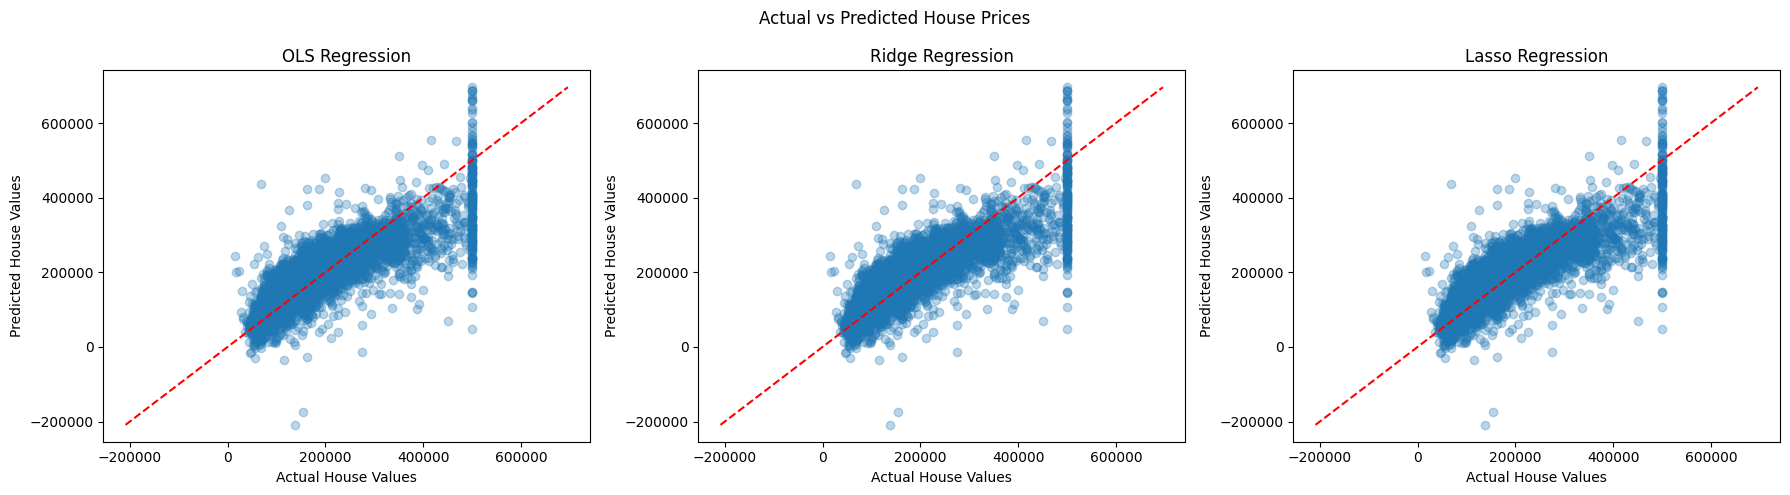

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

predictions = [
    (y_pred_ols, "OLS Regression"),
    (y_pred_ridge, "Ridge Regression"),
    (y_pred_lasso, "Lasso Regression")
]

for ax, (pred, title) in zip(axes, predictions):

    ax.scatter(y_test, pred, alpha=0.3)

    min_val = min(y_test.min(), pred.min())
    max_val = max(y_test.max(), pred.max())

    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        'r--'
    )

    ax.set_title(title)
    ax.set_xlabel("Actual House Values")
    ax.set_ylabel("Predicted House Values")

plt.suptitle("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()

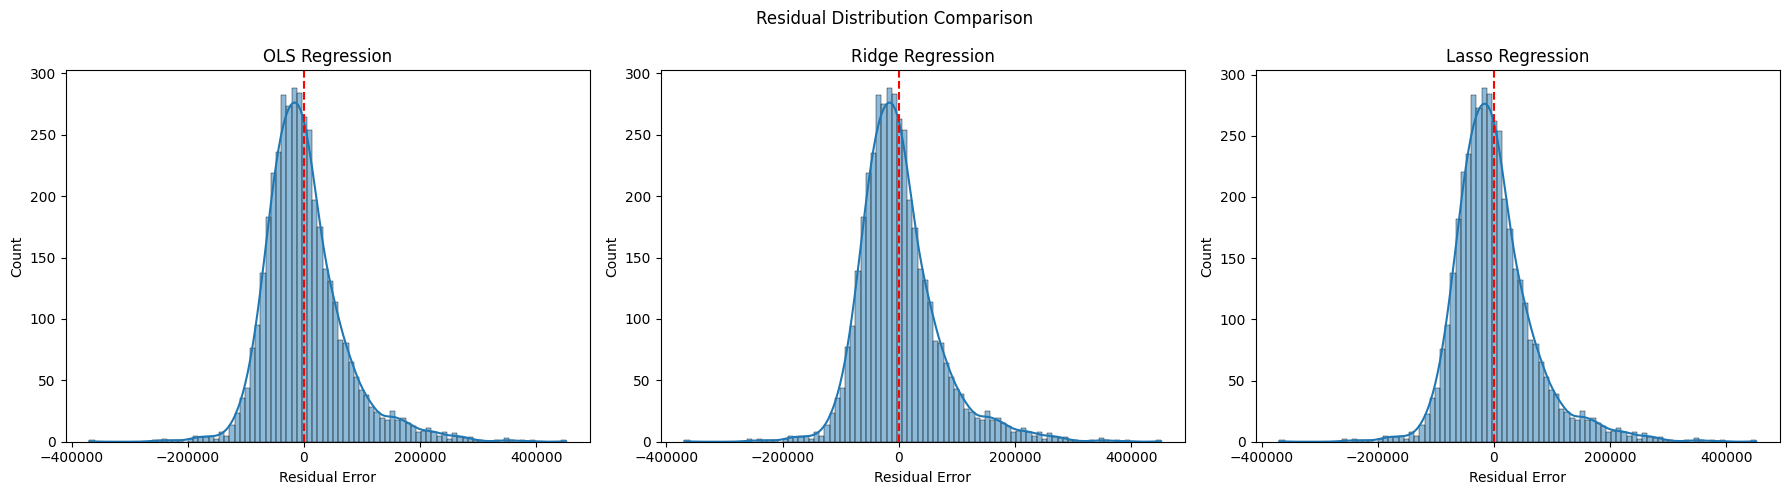

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

predictions = [
    (y_pred_ols, "OLS Regression"),
    (y_pred_ridge, "Ridge Regression"),
    (y_pred_lasso, "Lasso Regression")
]

for ax, (pred, title) in zip(axes, predictions):

    residuals = y_test - pred

    sns.histplot(
        residuals,
        kde=True,
        ax=ax
    )

    ax.axvline(0, color='red', linestyle='--')

    ax.set_title(title)
    ax.set_xlabel("Residual Error")

plt.suptitle("Residual Distribution Comparison")
plt.tight_layout()
plt.show()

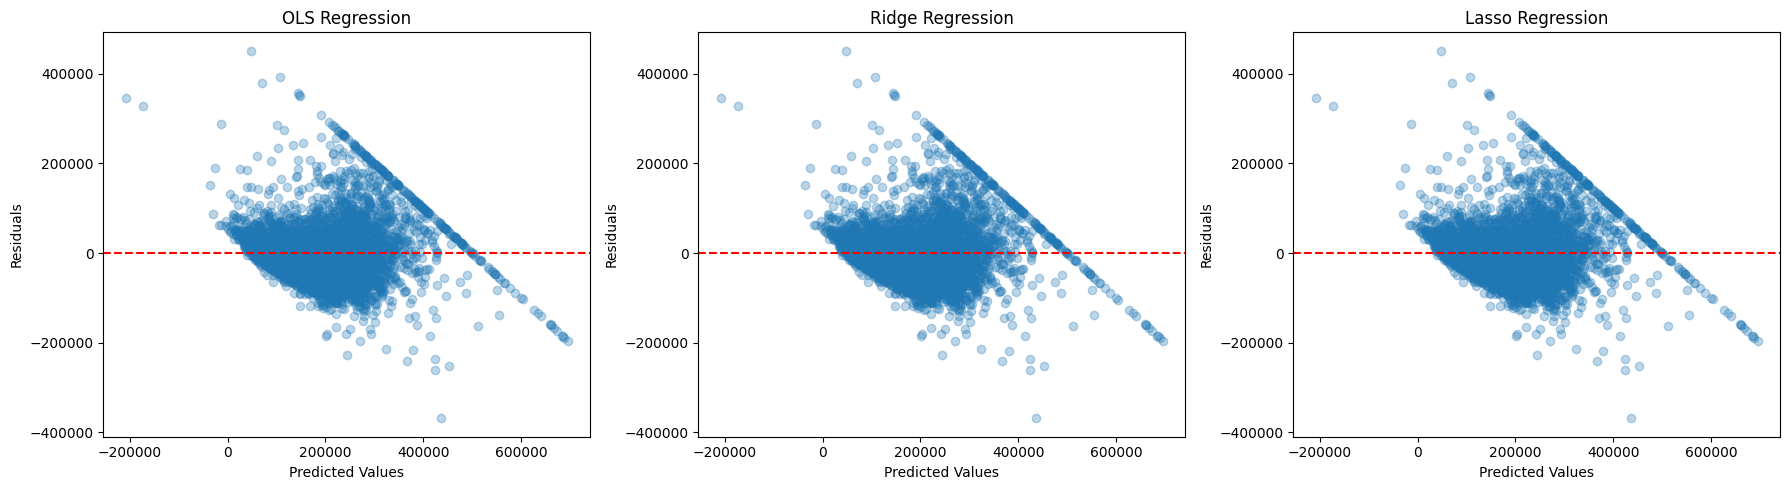

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (pred, title) in zip(axes, predictions):

    residuals = y_test - pred

    ax.scatter(pred, residuals, alpha=0.3)
    ax.axhline(0, color='red', linestyle='--')

    ax.set_title(title)
    ax.set_xlabel("Predicted Values")
    ax.set_ylabel("Residuals")

plt.tight_layout()
plt.show()

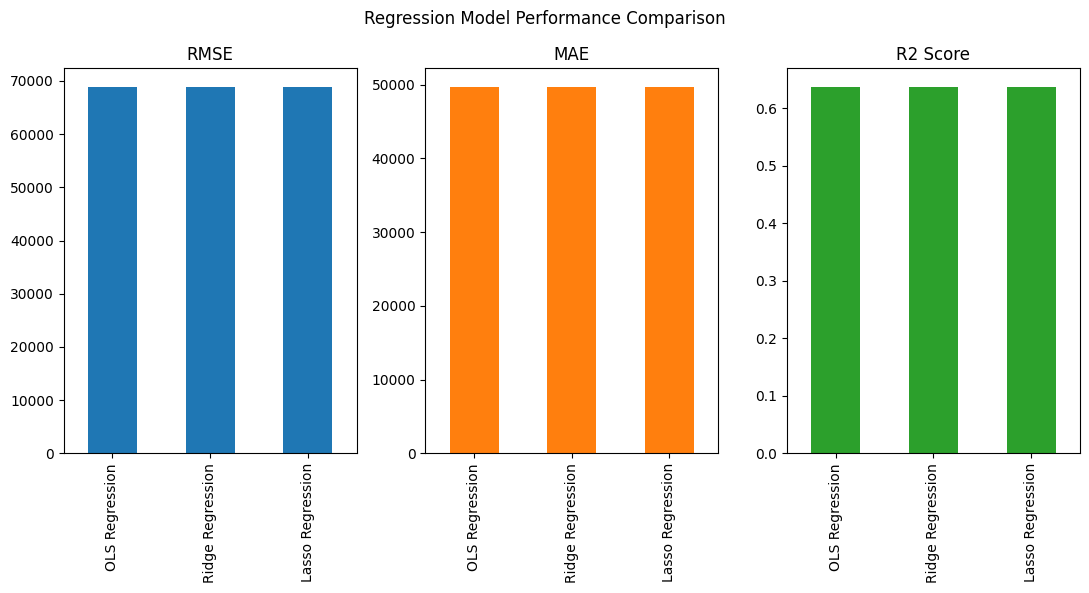

In [24]:
# Compare regression models visually

results_df.T[['RMSE', 'MAE', 'R2 Score']].plot(
    kind='bar',
    figsize=(11, 6),
    subplots=True,
    layout=(1, 3),
    legend=False
)

plt.suptitle("Regression Model Performance Comparison")
plt.tight_layout()
plt.show()

In [25]:
# Identify best model based on evaluation metrics

best_rmse_model = results_df.loc['RMSE'].idxmin()

best_mae_model = results_df.loc['MAE'].idxmin()

best_r2_model = results_df.loc['R2 Score'].idxmax()

print("BEST MODEL COMPARISON")
print("-" * 40)

print("Lowest RMSE:", best_rmse_model)
print("Lowest MAE:", best_mae_model)
print("Highest R2:", best_r2_model)

display(results_df.round(4))

BEST MODEL COMPARISON
----------------------------------------
Lowest RMSE: OLS Regression
Lowest MAE: OLS Regression
Highest R2: OLS Regression


,OLS Regression,Ridge Regression,Lasso Regression
RMSE,68917.3167,68925.9572,68918.6758
MAE,49709.5395,49715.8408,49710.2715
R2 Score,0.6375,0.6375,0.6375



# Final Conclusion

In this project, an end-to-end Real Estate Housing Price Prediction system was developed using the California Housing dataset.

The project involved:
- Exploratory Data Analysis (EDA)
- Missing value handling
- Feature engineering
- Correlation analysis
- Categorical encoding
- Feature scaling
- Model training and hyperparameter tuning

Three regression algorithms were implemented:
1. Ordinary Least Squares (OLS)
2. Ridge Regression (L2)
3. Lasso Regression (L1)

GridSearchCV was used to identify suitable regularization parameters for Ridge and Lasso Regression.

## Model Performance

| Model | RMSE | MAE | R2 Score |
|---|---:|---:|---:|
| OLS | 68917.32 | 49709.54 | 0.6375 |
| Ridge | 68925.96 | 49715.84 | 0.6375 |
| Lasso | 68918.68 | 49710.27 | 0.6375 |

## Best Model

OLS Regression achieved the lowest RMSE and MAE among the three models.

All three models achieved approximately the same R2 score of 0.6375.

Therefore, OLS Regression performed marginally better on the test dataset.

## Learning Outcomes

This project provided practical experience in regression analysis, feature engineering, preprocessing pipelines, regularization techniques, hyperparameter tuning, and model evaluation using Python and Scikit-Learn.
